# Exploratory Data Analysis (EDA): Telecom Customer Churn

**Objective:** Understand which customer characteristics are associated with churn, so that we can build a better prediction model and suggest retention actions.

**Input:** `data/processed/telco_clean.csv` (output of `clean_data.py`)

**Target variable:** `churn` (1 = customer left, 0 = customer stayed)

**Contents**
1. Load the data
2. Target distribution
3. Churn rate by category
4. Numeric features
5. Correlation with churn
6. Summary of insights

## 1. Load the Data

We load the cleaned dataset created in the preprocessing step. In that step we removed leakage columns (such as churn score and satisfaction score), dropped identifiers and constant columns, and handled missing values.

**Expected shape:** 7,043 customers and 31 columns (30 features + 1 target).

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
df = pd.read_csv("../data/processed/telco_clean.csv")
df.shape, df["churn"].mean()

((7043, 31), np.float64(0.2653698707936959))

## 2. Target Distribution

**Why this matters:** Before modeling, we need to know how balanced the target is. If one class is much rarer, a model can look accurate while being useless.

**Observation:** About 73% of customers stayed and about 27% churned. This is a moderately **imbalanced** dataset.

**Implication:** Accuracy alone would be misleading, because a model that always predicts "stayed" would score about 73%. We will use ROC-AUC, PR-AUC, recall and F1 instead, and use stratified splits and class weights during modeling.

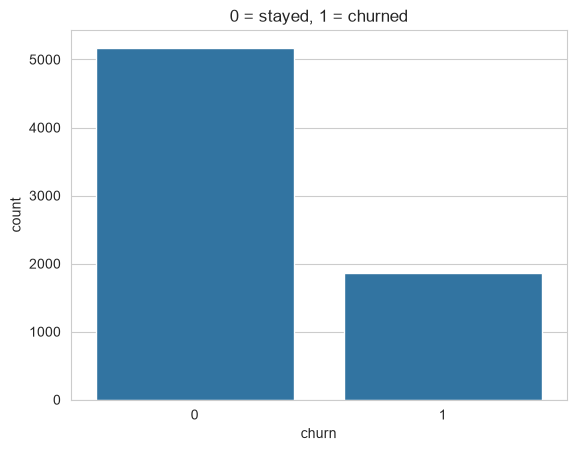

In [5]:
sns.countplot(x="churn", data=df)
plt.title("0 = stayed, 1 = churned")
plt.savefig("../reports/figures/churn_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Churn Rate by Category

**Why this matters:** Comparing churn rates across groups shows which customer segments are at higher risk. Each chart shows the percentage of customers who churned within each category.

**Key observations:**
- **Contract type is the strongest pattern.** Month-to-month customers churn at about 46%, compared with about 11% for one-year and about 2.5% for two-year contracts.
- **Internet type:** Fiber optic customers churn the most (about 41%), compared with DSL (about 19%) and customers with no internet (about 7%).
- **Payment method:** Credit card customers churn far less (about 14.5%) than bank withdrawal (about 34%) or mailed check (about 37%) customers.
- **Support services:** Customers without premium tech support (about 31%) or online security (about 31%) churn roughly twice as often as those with them (about 15%).
- **Offers:** Offer E has the highest churn (about 53%), while Offer A has the lowest (about 7%). This suggests some offers attract less loyal customers.
- **Social ties:** Married customers and customers who referred a friend churn less.

**Caution:** These are associations, not proven causes. Customers on longer contracts may simply be more loyal to begin with.

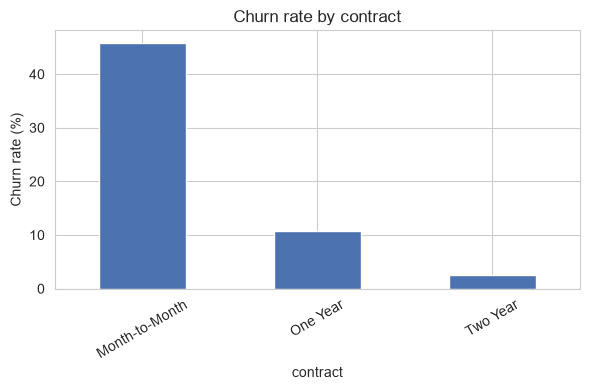

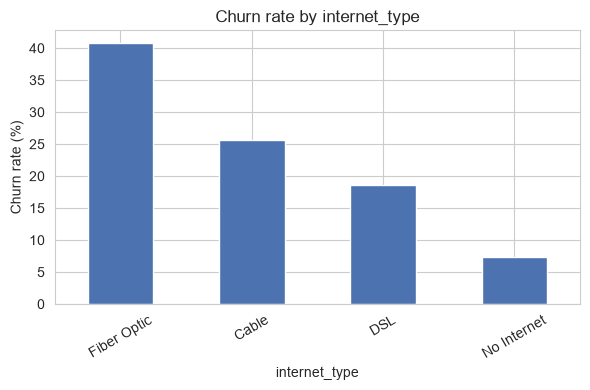

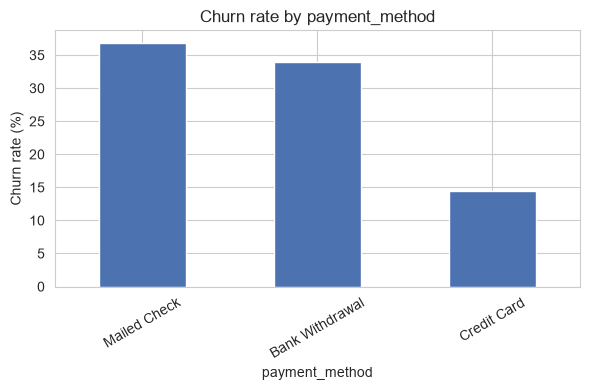

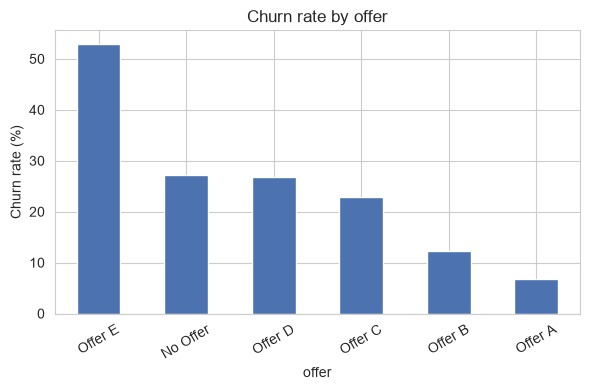

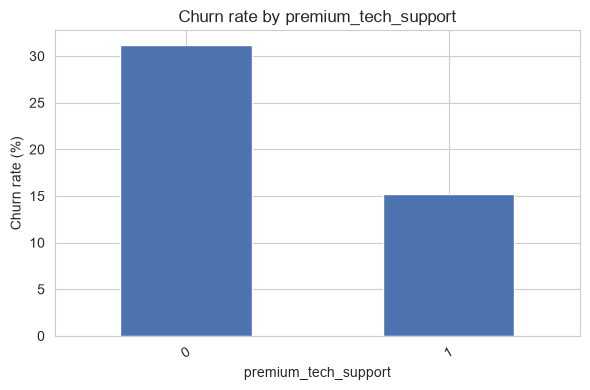

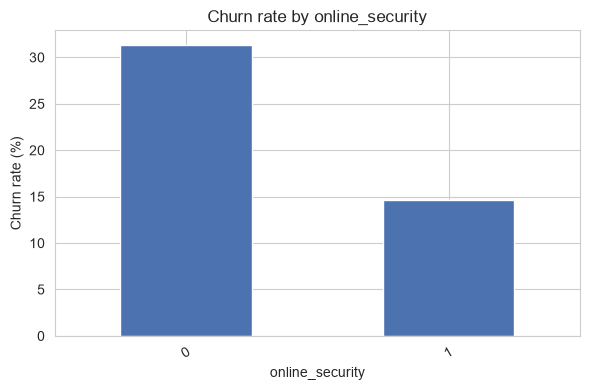

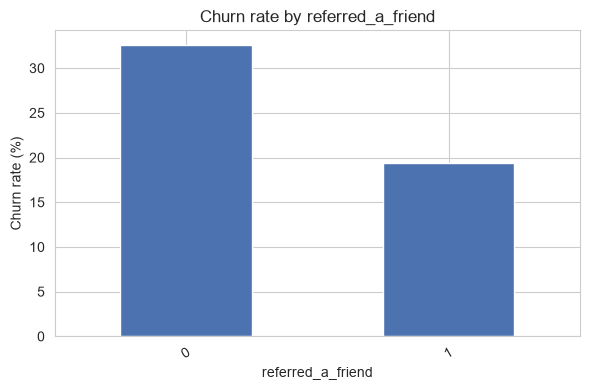

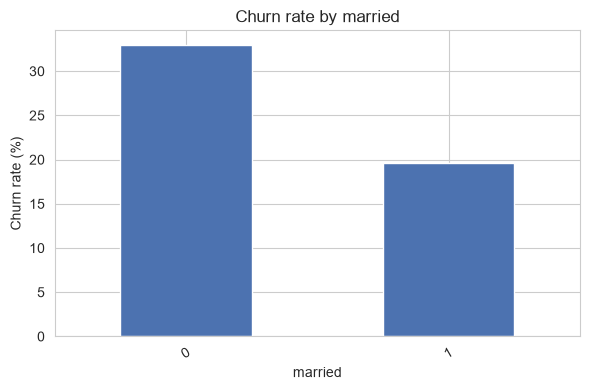

In [6]:
def churn_rate_plot(col):
    rate = df.groupby(col)["churn"].mean().sort_values(ascending=False) * 100
    rate.plot(kind="bar", figsize=(6, 4), color="#4C72B0")
    plt.ylabel("Churn rate (%)")
    plt.title(f"Churn rate by {col}")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.savefig(f"../reports/figures/churn_by_{col}.png", dpi=150)
    plt.show()

for col in ["contract", "internet_type", "payment_method", "offer",
            "premium_tech_support", "online_security", "referred_a_friend", "married"]:
    churn_rate_plot(col)

## 4. Numeric Features

**Why this matters:** Histograms split by churn show whether churners and non-churners have different distributions for numeric variables.

**Key observations:**
- **Tenure:** Churners have a much shorter average tenure (about 18 months) than customers who stayed (about 38 months). Risk is highest early in the customer lifecycle.
- **Monthly charge:** Churners pay more per month on average (about $74 vs about $61), so price sensitivity may play a role.
- **Age:** Churners are slightly older on average (about 50 vs about 45 years).

**Implication:** Tenure and monthly charge are likely to be important predictors. We may create features such as tenure groups and number of services in the feature engineering step.

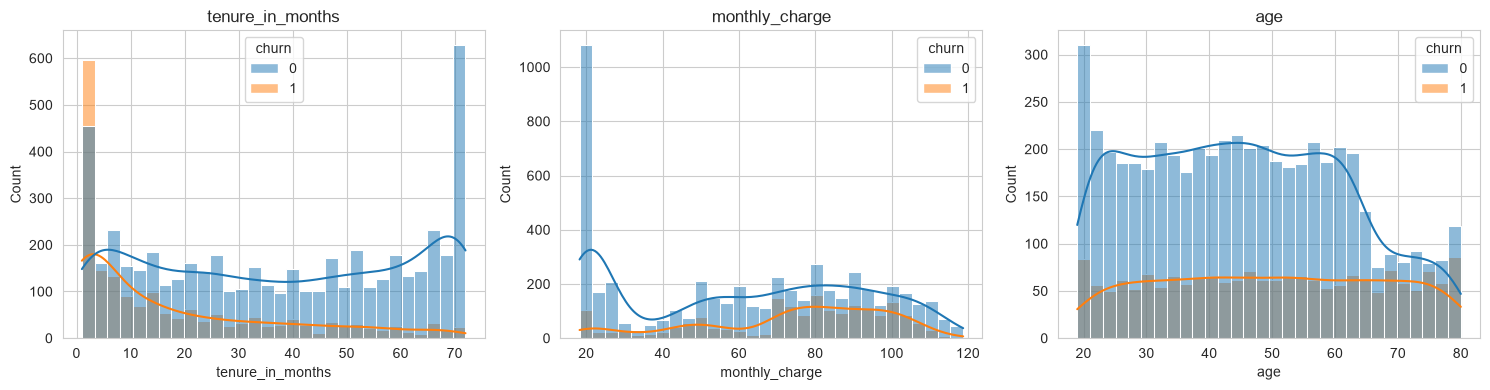

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["tenure_in_months", "monthly_charge", "age"]):
    sns.histplot(data=df, x=col, hue="churn", kde=True, bins=30, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.savefig("../reports/figures/numeric_distributions.png", dpi=150)
plt.show()

## 5. Correlation with Churn

**Why this matters:** Correlation gives a quick ranking of which numeric and binary features move together with churn. A negative value means a higher feature value goes with less churn, and a positive value means more churn.

**Key observations:**
- **Strongest negative:** `tenure_in_months` (about -0.35) and `number_of_referrals` (about -0.29). Loyal, well-connected customers are less likely to leave.
- **Strongest positive:** `monthly_charge`, `paperless_billing` (both about +0.19) and `unlimited_data` (about +0.17).
- Most features have weak linear correlation, so the model will need to combine many features and may benefit from non-linear methods such as XGBoost.

**Note:** Correlation only captures linear relationships, so a low value does not mean a feature is useless.

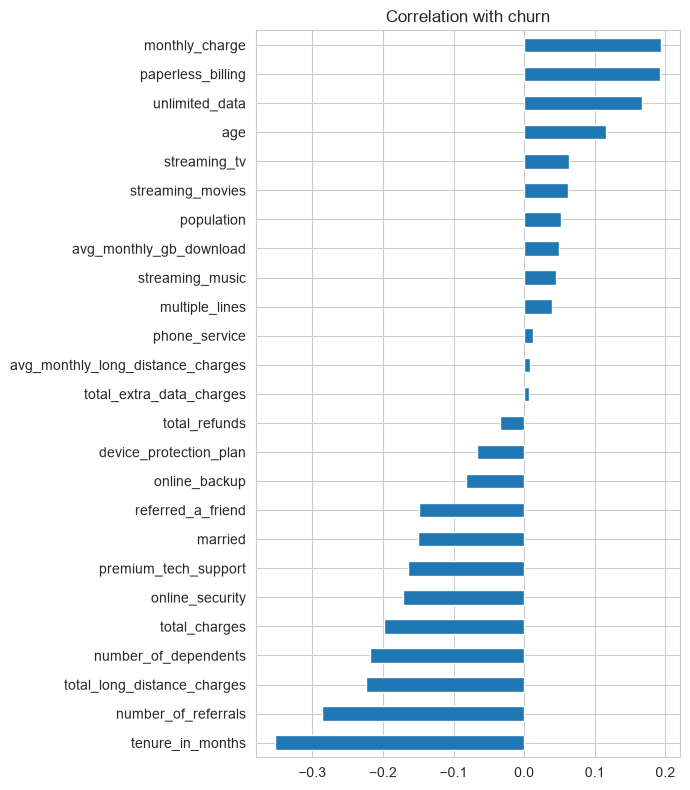

In [8]:
corr = df.corr(numeric_only=True)["churn"].drop("churn").sort_values()
corr.plot(kind="barh", figsize=(7, 8))
plt.title("Correlation with churn")
plt.tight_layout()
plt.savefig("../reports/figures/correlation_with_churn.png", dpi=150)
plt.show()

## 6. Summary of Insights

1. **Churn rate is about 26.5%**, so the target is imbalanced and needs suitable metrics.
2. **Contract type is the biggest driver.** Month-to-month customers churn about 18 times more than two-year customers.
3. **New customers are the most at risk.** Short tenure is strongly linked to churn.
4. **Fiber optic customers churn more** than other internet types, which may point to a price or service-quality issue worth investigating.
5. **Support and security services are linked to loyalty.** Customers with tech support or online security churn about half as often.
6. **Payment method matters.** Credit card customers are the most stable group.
7. **Some promotional offers (notably Offer E) are linked to very high churn.**

**Next steps:**
- Create new features (number of services, tenure groups).
- Split data into train and test sets (stratified).
- Build a preprocessing pipeline and train baseline and advanced models.

**Limitations:** This is a single snapshot of data, and the patterns shown are associations, not causal effects.